# Retail Sales Forecasting and Customer Analytics
## Sales Forecasting

### Purpose

The purpose of this analysis is to develop and evaluate forecasting methods for historical delivered product sales.

The exploratory analysis identified a clear temporal pattern in sales, but also showed that the earliest part of the dataset is sparse. Therefore, the forecasting period and aggregation frequency will be evaluated before selecting any forecasting model.

The sales time series will first be prepared and checked for completeness, trend and temporal structure. Forecasting models will then be compared using a time-based validation approach and suitable error metrics. A simple benchmark model will also be included so that more advanced methods are only considered useful if they improve forecasting performance.

The final model will be selected using both predictive performance and suitability for the available data. Its limitations will be considered before the forecast is integrated into the Power BI dashboard.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Define project folders
project_path = Path.cwd().parent
cleaned_data_path = project_path / "02_Cleaned_Data"

# Load the prepared delivered transaction dataset
transactions = pd.read_csv(
    cleaned_data_path / "transactions_clean.csv"
)

# Convert purchase timestamp to datetime
transactions["order_purchase_timestamp"] = pd.to_datetime(
    transactions["order_purchase_timestamp"],
    errors="coerce"
)

print("Dataset shape:", transactions.shape)
print("Missing purchase dates:",
      transactions["order_purchase_timestamp"].isna().sum())

print("Earliest purchase:",
      transactions["order_purchase_timestamp"].min())

print("Latest purchase:",
      transactions["order_purchase_timestamp"].max())

print("Total product sales:",
      round(transactions["sales_value"].sum(), 2))

Dataset shape: (110197, 27)
Missing purchase dates: 0
Earliest purchase: 2016-09-15 12:16:38
Latest purchase: 2018-08-29 15:00:37
Total product sales: 13221498.11


In [2]:
# Create a date field for time-series analysis
transactions["purchase_date"] = (
    transactions["order_purchase_timestamp"].dt.normalize()
)

# Focus on the main continuous observation period
forecast_data = transactions[
    (transactions["purchase_date"] >= "2017-01-01") &
    (transactions["purchase_date"] <= "2018-08-31")
].copy()

print("Forecasting-period rows:", len(forecast_data))

print("Start date:",
      forecast_data["purchase_date"].min())

print("End date:",
      forecast_data["purchase_date"].max())

# Aggregate product sales at different frequencies
daily_sales = (
    forecast_data
    .set_index("purchase_date")["sales_value"]
    .resample("D")
    .sum()
)

weekly_sales = (
    forecast_data
    .set_index("purchase_date")["sales_value"]
    .resample("W")
    .sum()
)

monthly_sales = (
    forecast_data
    .set_index("purchase_date")["sales_value"]
    .resample("MS")
    .sum()
)

print("\nNumber of daily observations:", len(daily_sales))
print("Number of weekly observations:", len(weekly_sales))
print("Number of monthly observations:", len(monthly_sales))

print("\nDays with zero sales:", (daily_sales == 0).sum())
print("Weeks with zero sales:", (weekly_sales == 0).sum())
print("Months with zero sales:", (monthly_sales == 0).sum())

print("\nFirst 5 weekly observations:")
print(weekly_sales.head())

print("\nLast 5 weekly observations:")
print(weekly_sales.tail())

Forecasting-period rows: 109880
Start date: 2017-01-05 00:00:00
End date: 2018-08-29 00:00:00

Number of daily observations: 602
Number of weekly observations: 87
Number of monthly observations: 20

Days with zero sales: 0
Weeks with zero sales: 0
Months with zero sales: 0

First 5 weekly observations:
purchase_date
2017-01-08     3114.96
2017-01-15    10969.66
2017-01-22    23316.80
2017-01-29    53679.16
2017-02-05    68718.18
Freq: W-SUN, Name: sales_value, dtype: float64

Last 5 weekly observations:
purchase_date
2018-08-05    271314.44
2018-08-12    270236.80
2018-08-19    243458.02
2018-08-26    125412.50
2018-09-02     10565.86
Freq: W-SUN, Name: sales_value, dtype: float64


In [3]:
# Create weekly sales using complete Monday-Sunday weeks only

weekly_sales_complete = weekly_sales[
    (weekly_sales.index >= "2017-01-15") &
    (weekly_sales.index <= "2018-08-26")
].copy()

print("Complete weekly observations:",
      len(weekly_sales_complete))

print("First week ending:",
      weekly_sales_complete.index.min())

print("Last week ending:",
      weekly_sales_complete.index.max())

print("\nFirst 5 weeks:")
print(weekly_sales_complete.head())

print("\nLast 5 weeks:")
print(weekly_sales_complete.tail())

print("\nWeekly sales summary:")
print(weekly_sales_complete.describe())

Complete weekly observations: 85
First week ending: 2017-01-15 00:00:00
Last week ending: 2018-08-26 00:00:00

First 5 weeks:
purchase_date
2017-01-15    10969.66
2017-01-22    23316.80
2017-01-29    53679.16
2017-02-05    68718.18
2017-02-12    75998.99
Freq: W-SUN, Name: sales_value, dtype: float64

Last 5 weeks:
purchase_date
2018-07-29    236498.42
2018-08-05    271314.44
2018-08-12    270236.80
2018-08-19    243458.02
2018-08-26    125412.50
Freq: W-SUN, Name: sales_value, dtype: float64

Weekly sales summary:
count        85.000000
mean     154909.956588
std       70348.084757
min       10969.660000
25%      103260.540000
50%      141792.880000
75%      210871.980000
max      397906.240000
Name: sales_value, dtype: float64


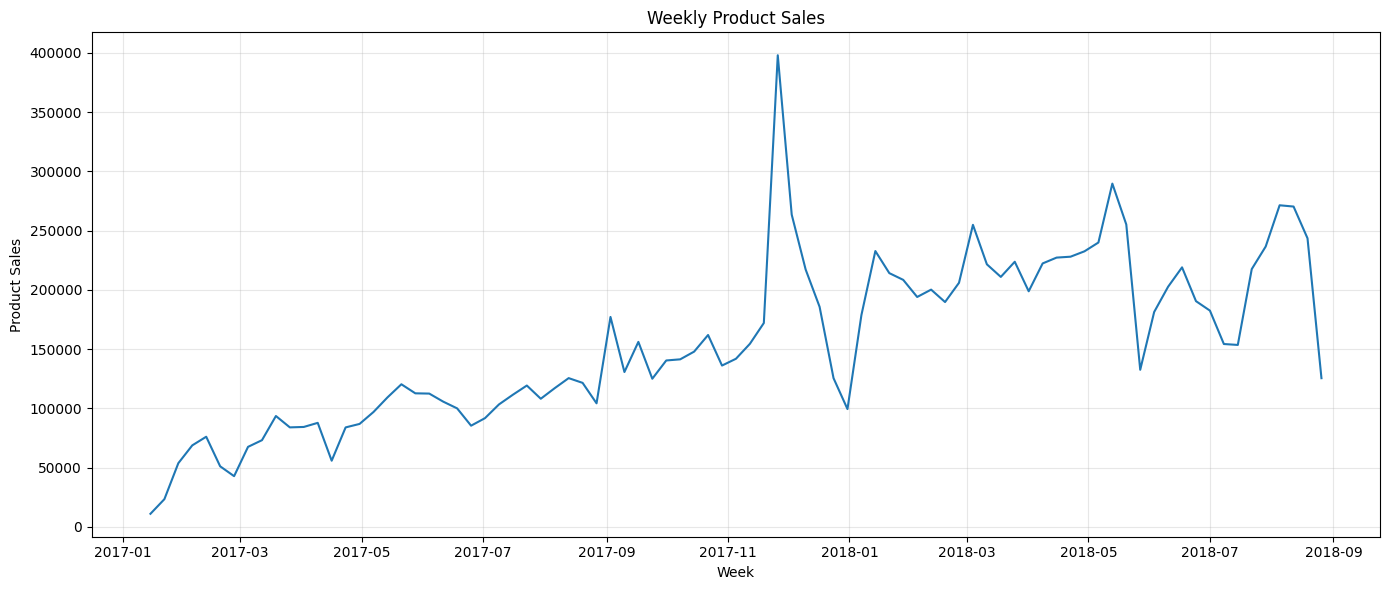

In [4]:
# Plot complete weekly product sales

plt.figure(figsize=(14, 6))

plt.plot(
    weekly_sales_complete.index,
    weekly_sales_complete.values
)

plt.title("Weekly Product Sales")
plt.xlabel("Week")
plt.ylabel("Product Sales")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Forecasting Frequency

Daily, weekly and monthly sales frequencies were compared before model development. The main continuous observation period contained 602 daily observations, 87 weekly observations and only 20 monthly observations. No zero-sales periods were identified.

Weekly aggregation was selected because it provides more observations for model training and evaluation than monthly aggregation while reducing some of the short-term variation present in daily sales. The first and final partial weeks were excluded, leaving 85 complete weekly observations from the week ending 15 January 2017 to the week ending 26 August 2018.

The weekly series shows an overall increase in product sales across the observation period, together with substantial short-term variation and several peaks. These observations will be retained unless there is evidence that they result from data-quality problems, because unusual sales values may represent genuine business activity.

In [5]:
# Create chronological training and test sets

test_weeks = 12

train = weekly_sales_complete.iloc[:-test_weeks].copy()
test = weekly_sales_complete.iloc[-test_weeks:].copy()

print("Total observations:", len(weekly_sales_complete))
print("Training observations:", len(train))
print("Test observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTest period:")
print(test.index.min(), "to", test.index.max())

print("\nTraining sales summary:")
print(train.describe())

print("\nTest sales summary:")
print(test.describe())

Total observations: 85
Training observations: 73
Test observations: 12

Training period:
2017-01-15 00:00:00 to 2018-06-03 00:00:00

Test period:
2018-06-10 00:00:00 to 2018-08-26 00:00:00

Training sales summary:
count        73.000000
mean     146587.900137
std       70329.192630
min       10969.660000
25%       96876.150000
50%      130611.800000
75%      200137.440000
max      397906.240000
Name: sales_value, dtype: float64

Test sales summary:
count        12.000000
mean     205535.800000
std       46481.809218
min      125412.500000
25%      175372.145000
50%      210019.420000
75%      238238.320000
max      271314.440000
Name: sales_value, dtype: float64


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Naive benchmark:
# forecast every test week using the final training observation

naive_forecast = pd.Series(
    train.iloc[-1],
    index=test.index
)

# Calculate evaluation metrics
naive_mae = mean_absolute_error(
    test,
    naive_forecast
)

naive_rmse = np.sqrt(
    mean_squared_error(
        test,
        naive_forecast
    )
)

naive_mape = (
    np.mean(
        np.abs(
            (test - naive_forecast) / test
        )
    ) * 100
)

print("Last training value:",
      round(train.iloc[-1], 2))

print("\nNaive Benchmark Performance")
print("MAE:", round(naive_mae, 2))
print("RMSE:", round(naive_rmse, 2))
print("MAPE:", round(naive_mape, 2), "%")

Last training value: 181263.13

Naive Benchmark Performance
MAE: 42718.59
RMSE: 50691.96
MAPE: 20.42 %


In [7]:
# Four-week moving-average benchmark

moving_average_value = train.iloc[-4:].mean()

moving_average_forecast = pd.Series(
    moving_average_value,
    index=test.index
)

# Calculate evaluation metrics
ma_mae = mean_absolute_error(
    test,
    moving_average_forecast
)

ma_rmse = np.sqrt(
    mean_squared_error(
        test,
        moving_average_forecast
    )
)

ma_mape = (
    np.mean(
        np.abs(
            (test - moving_average_forecast) / test
        )
    ) * 100
)

print("Average of final 4 training weeks:",
      round(moving_average_value, 2))

print("\n4-Week Moving Average Performance")
print("MAE:", round(ma_mae, 2))
print("RMSE:", round(ma_rmse, 2))
print("MAPE:", round(ma_mape, 2), "%")

Average of final 4 training weeks: 214619.48

4-Week Moving Average Performance
MAE: 37447.95
RMSE: 45420.54
MAPE: 21.02 %


In [9]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/11.3 MB 6.7 MB/s eta 0:00:02
   --------- ------------------------------ 2.6/11.3 MB 6.9 MB/s eta 0:00:02
   -------------- ------------------------- 4.2/11.3 MB 6.8 MB/s eta 0:00:02
   -------------------- ------------------- 5.8/11.3 MB 6.9 MB/s eta 0:00:01
   ------------------------- -------------- 7.1/11.3 MB 6.8 MB/s eta 0:00:01
   ---------------------------- ----------- 8.1/11.3 MB 6.8 MB/s eta 0:00:01
   ----------------------------- ---------- 8.4/11.3 MB 6.6 MB/s eta 0:00:01
   --------------------------------- ------ 9.4/11.3 MB 5.6 MB/s eta 0:00:01
   -------------------------------------- - 11.0/11.3 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 5.6 MB/s eta 0:00:00
Using


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\trasc\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [10]:
import statsmodels

print("Statsmodels version:", statsmodels.__version__)

Statsmodels version: 0.15.0


In [11]:
from statsmodels.tsa.holtwinters import Holt

# Fit Holt's linear trend model to the training data
holt_model = Holt(
    train,
    initialization_method="estimated"
).fit(optimized=True)

# Forecast the 12-week test period
holt_forecast = holt_model.forecast(len(test))

# Align forecast dates with the test period
holt_forecast.index = test.index

# Calculate evaluation metrics
holt_mae = mean_absolute_error(
    test,
    holt_forecast
)

holt_rmse = np.sqrt(
    mean_squared_error(
        test,
        holt_forecast
    )
)

holt_mape = (
    np.mean(
        np.abs(
            (test - holt_forecast) / test
        )
    ) * 100
)

print("Holt Trend Model Performance")
print("MAE:", round(holt_mae, 2))
print("RMSE:", round(holt_rmse, 2))
print("MAPE:", round(holt_mape, 2), "%")

print("\nForecast values:")
print(holt_forecast.round(2))

Holt Trend Model Performance
MAE: 36708.38
RMSE: 43930.28
MAPE: 19.77 %

Forecast values:
purchase_date
2018-06-10    188805.45
2018-06-17    191082.15
2018-06-24    193358.85
2018-07-01    195635.55
2018-07-08    197912.26
2018-07-15    200188.96
2018-07-22    202465.66
2018-07-29    204742.37
2018-08-05    207019.07
2018-08-12    209295.77
2018-08-19    211572.47
2018-08-26    213849.18
Freq: W-SUN, dtype: float64


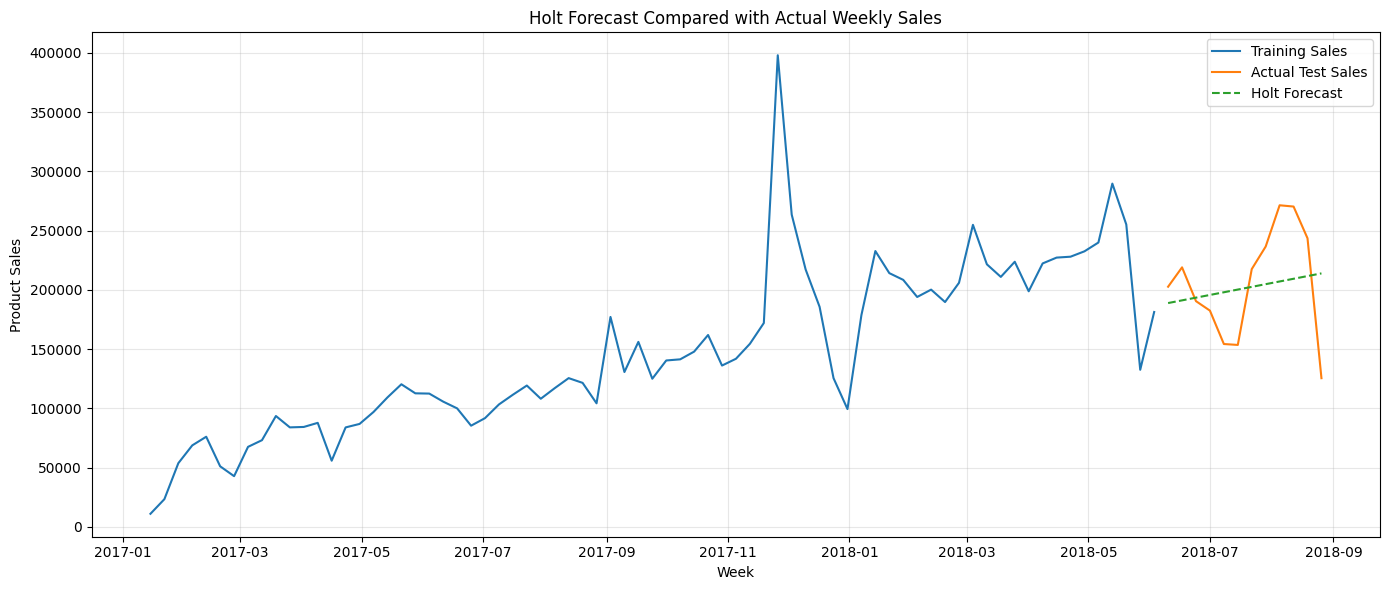

In [12]:
# Compare training data, actual test sales and Holt forecast

plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train.values,
    label="Training Sales"
)

plt.plot(
    test.index,
    test.values,
    label="Actual Test Sales"
)

plt.plot(
    holt_forecast.index,
    holt_forecast.values,
    label="Holt Forecast",
    linestyle="--"
)

plt.title("Holt Forecast Compared with Actual Weekly Sales")
plt.xlabel("Week")
plt.ylabel("Product Sales")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Initial Model Evaluation

Three forecasting approaches were initially evaluated using the same 12-week chronological test period. The naive benchmark produced an MAE of 42,718.59, RMSE of 50,691.96 and MAPE of 20.42%. The four-week moving-average approach reduced MAE and RMSE to 37,447.95 and 45,420.54 respectively, although its MAPE increased slightly to 21.02%.

Holt's trend model produced the strongest overall results at this stage, with an MAE of 36,708.38, RMSE of 43,930.28 and MAPE of 19.77%. This indicates that modelling the underlying trend provided some improvement over the simpler benchmarks.

However, the improvement was moderate rather than substantial. Visual comparison also shows that Holt's model produces a smooth increasing forecast and does not capture several of the short-term peaks and falls observed in the test data. Therefore, the model should not yet be selected as the final forecasting approach. Further model comparison is required.

In [13]:
# Fit Holt's damped-trend model

holt_damped_model = Holt(
    train,
    damped_trend=True,
    initialization_method="estimated"
).fit(optimized=True)

# Forecast the test period
holt_damped_forecast = holt_damped_model.forecast(len(test))

# Align dates with the test set
holt_damped_forecast.index = test.index

# Calculate evaluation metrics
holt_damped_mae = mean_absolute_error(
    test,
    holt_damped_forecast
)

holt_damped_rmse = np.sqrt(
    mean_squared_error(
        test,
        holt_damped_forecast
    )
)

holt_damped_mape = (
    np.mean(
        np.abs(
            (test - holt_damped_forecast) / test
        )
    ) * 100
)

print("Holt Damped-Trend Model Performance")
print("MAE:", round(holt_damped_mae, 2))
print("RMSE:", round(holt_damped_rmse, 2))
print("MAPE:", round(holt_damped_mape, 2), "%")

print("\nForecast values:")
print(holt_damped_forecast.round(2))

Holt Damped-Trend Model Performance
MAE: 45779.71
RMSE: 58271.19
MAPE: 27.81 %

Forecast values:
purchase_date
2018-06-10    235103.00
2018-06-17    236786.00
2018-06-24    238446.63
2018-07-01    240085.17
2018-07-08    241701.93
2018-07-15    243297.19
2018-07-22    244871.23
2018-07-29    246424.35
2018-08-05    247956.81
2018-08-12    249468.90
2018-08-19    250960.88
2018-08-26    252433.02
Freq: W-SUN, dtype: float64


<Figure size 1200x500 with 0 Axes>

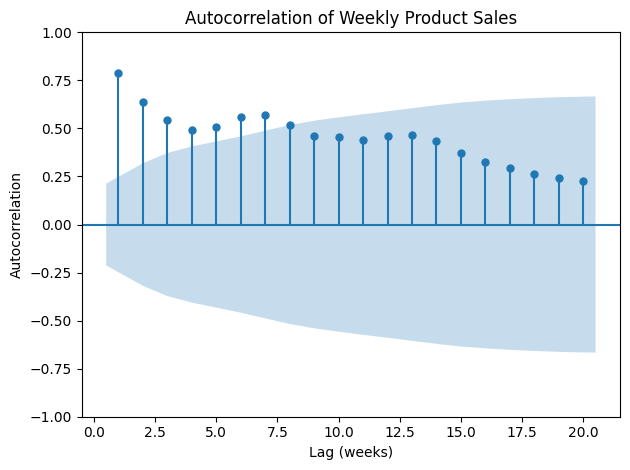

In [14]:
from statsmodels.graphics.tsaplots import plot_acf

# Examine autocorrelation in the complete weekly sales series

plt.figure(figsize=(12, 5))

plot_acf(
    weekly_sales_complete,
    lags=20,
    zero=False
)

plt.title("Autocorrelation of Weekly Product Sales")
plt.xlabel("Lag (weeks)")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

In [15]:
from statsmodels.tsa.arima.model import ARIMA

# Compare a small set of non-seasonal ARIMA configurations
arima_orders = [
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

arima_results = []

for order in arima_orders:
    try:
        model = ARIMA(
            train,
            order=order
        )

        fitted_model = model.fit()

        arima_results.append({
            "order": order,
            "AIC": fitted_model.aic
        })

    except Exception as error:
        print(f"ARIMA{order} failed: {error}")

arima_comparison = pd.DataFrame(
    arima_results
).sort_values("AIC")

print("ARIMA Training Comparison:")
print(arima_comparison.to_string(index=False))

ARIMA Training Comparison:
    order         AIC
(2, 1, 2) 1731.954703
(0, 1, 2) 1733.355223
(1, 1, 1) 1733.692874
(1, 1, 2) 1734.595363
(2, 1, 1) 1734.912761
(0, 1, 1) 1738.741510
(1, 1, 0) 1740.260078
(2, 1, 0) 1740.442320


C:\Users\trasc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\trasc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [16]:
# Fit the selected ARIMA model using training data only

arima_model = ARIMA(
    train,
    order=(2, 1, 2)
).fit()

# Forecast the 12-week test period
arima_forecast = arima_model.forecast(
    steps=len(test)
)

# Align forecast dates with test data
arima_forecast.index = test.index

# Calculate evaluation metrics
arima_mae = mean_absolute_error(
    test,
    arima_forecast
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test,
        arima_forecast
    )
)

arima_mape = (
    np.mean(
        np.abs(
            (test - arima_forecast) / test
        )
    ) * 100
)

print("ARIMA(2,1,2) Performance")
print("MAE:", round(arima_mae, 2))
print("RMSE:", round(arima_rmse, 2))
print("MAPE:", round(arima_mape, 2), "%")

print("\nForecast values:")
print(arima_forecast.round(2))

ARIMA(2,1,2) Performance
MAE: 44230.28
RMSE: 52597.02
MAPE: 25.1 %

Forecast values:
purchase_date
2018-06-10    211567.67
2018-06-17    230804.58
2018-06-24    238988.89
2018-07-01    238859.85
2018-07-08    234030.58
2018-07-15    227718.98
2018-07-22    222122.98
2018-07-29    218316.85
2018-08-05    216469.91
2018-08-12    216194.47
2018-08-19    216881.61
2018-08-26    217946.91
Freq: W-SUN, Name: predicted_mean, dtype: float64


C:\Users\trasc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


### ARIMA Evaluation

A small set of non-seasonal ARIMA specifications was compared using the training data. ARIMA(2,1,2) produced the lowest AIC of the candidate models and was therefore selected for out-of-sample evaluation.

On the 12-week test period, ARIMA(2,1,2) produced an MAE of 44,230.28, RMSE of 52,597.02 and MAPE of 25.10%. These results were weaker than the Holt trend model across all three evaluation metrics.

The result demonstrates that the more complex ARIMA approach did not provide improved forecasting accuracy for this dataset. The available weekly series contains only 85 complete observations and substantial short-term variation, which limits the amount of temporal structure that can be estimated reliably. Model selection will therefore be based on observed out-of-sample performance rather than model complexity.

In [18]:
# Compare all forecasting models

model_comparison = pd.DataFrame({
    "Model": [
        "Naive",
        "4-Week Moving Average",
        "Holt Trend",
        "Holt Damped Trend",
        "ARIMA(2,1,2)"
    ],
    "MAE": [
        naive_mae,
        ma_mae,
        holt_mae,
        holt_damped_mae,
        arima_mae
    ],
    "RMSE": [
        naive_rmse,
        ma_rmse,
        holt_rmse,
        holt_damped_rmse,
        arima_rmse
    ],
    "MAPE (%)": [
        naive_mape,
        ma_mape,
        holt_mape,
        holt_damped_mape,
        arima_mape
    ]
})

model_comparison = model_comparison.sort_values(
    "RMSE"
).reset_index(drop=True)

print("Forecasting Model Comparison:")
print(model_comparison.round(2).to_string(index=False))

Forecasting Model Comparison:
                Model      MAE     RMSE  MAPE (%)
           Holt Trend 36708.38 43930.28     19.77
4-Week Moving Average 37447.95 45420.54     21.02
                Naive 42718.59 50691.96     20.42
         ARIMA(2,1,2) 44230.28 52597.02     25.10
    Holt Damped Trend 45779.71 58271.19     27.81


In [19]:
# Calculate Holt improvement over the naive benchmark

mae_improvement = (
    (naive_mae - holt_mae) / naive_mae
) * 100

rmse_improvement = (
    (naive_rmse - holt_rmse) / naive_rmse
) * 100

mape_improvement = (
    (naive_mape - holt_mape) / naive_mape
) * 100

print("Holt Trend Improvement over Naive Benchmark")
print("MAE improvement:",
      round(mae_improvement, 2), "%")

print("RMSE improvement:",
      round(rmse_improvement, 2), "%")

print("MAPE improvement:",
      round(mape_improvement, 2), "%")

Holt Trend Improvement over Naive Benchmark
MAE improvement: 14.07 %
RMSE improvement: 13.34 %
MAPE improvement: 3.16 %


### Final Model Selection

Holt's trend model was selected as the final forecasting approach because it achieved the strongest out-of-sample performance across the three evaluation metrics. It produced an MAE of 36,708.38, RMSE of 43,930.28 and MAPE of 19.77%.

Compared with the naive benchmark, Holt reduced MAE by 14.07% and RMSE by 13.34%. The improvement in MAPE was smaller at 3.16%, showing that the improvement was useful but not substantial across every measure.

The four-week moving average performed relatively well but was weaker than Holt overall. More complex approaches did not improve the results: ARIMA(2,1,2) produced a MAPE of 25.10%, while the damped-trend Holt model produced 27.81%.

Holt was therefore selected based on observed test performance rather than model complexity. However, the model does not reproduce the substantial short-term fluctuations visible in weekly sales. The available time series is also relatively short, containing 85 complete weekly observations. These factors limit forecast certainty and mean that the resulting forecast should be treated as a planning estimate rather than a guaranteed future sales outcome.

In [20]:
# Refit the selected Holt model using all complete historical weeks

final_holt_model = Holt(
    weekly_sales_complete,
    initialization_method="estimated"
).fit(optimized=True)

# Generate a 12-week future forecast
forecast_horizon = 12

future_forecast = final_holt_model.forecast(
    forecast_horizon
)

print("Future Forecast - 12 Weeks")
print(future_forecast.round(2))

print("\nForecast summary:")
print("First forecast:", round(future_forecast.iloc[0], 2))
print("Final forecast:", round(future_forecast.iloc[-1], 2))
print("Average weekly forecast:", round(future_forecast.mean(), 2))

Future Forecast - 12 Weeks
2018-09-02    161839.56
2018-09-09    163490.81
2018-09-16    165142.06
2018-09-23    166793.32
2018-09-30    168444.57
2018-10-07    170095.83
2018-10-14    171747.08
2018-10-21    173398.34
2018-10-28    175049.59
2018-11-04    176700.84
2018-11-11    178352.10
2018-11-18    180003.35
Freq: W-SUN, dtype: float64

Forecast summary:
First forecast: 161839.56
Final forecast: 180003.35
Average weekly forecast: 170921.45


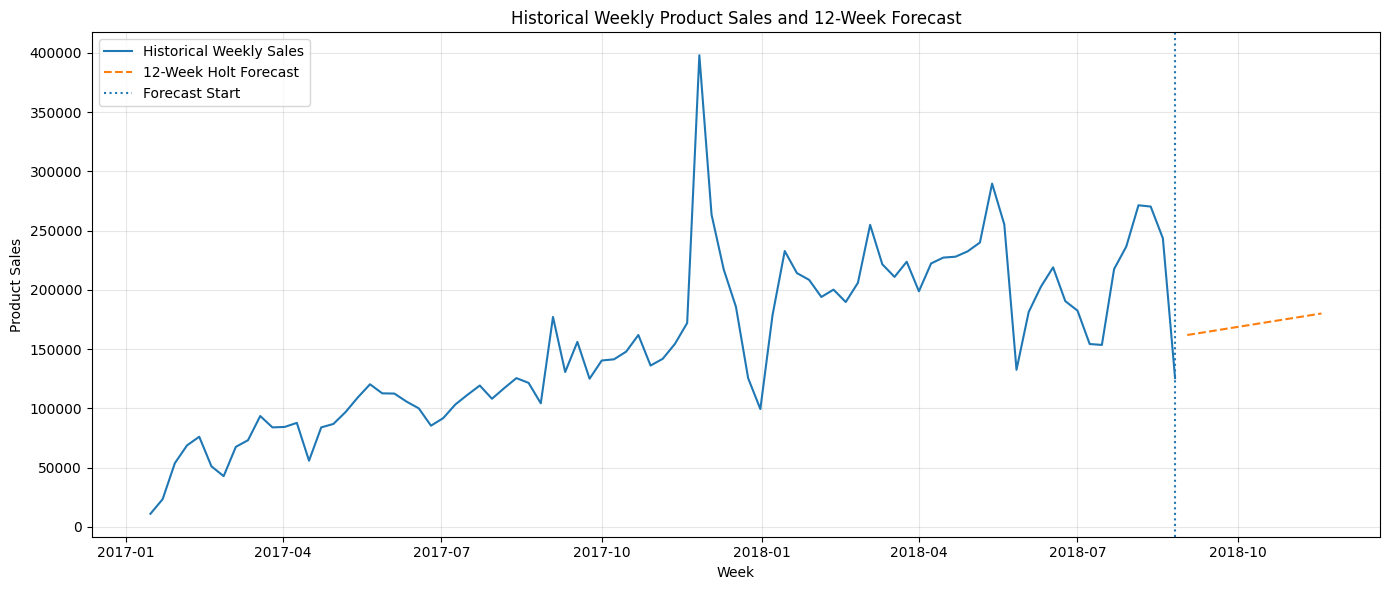

In [21]:
# Plot historical weekly sales and final 12-week forecast

plt.figure(figsize=(14, 6))

plt.plot(
    weekly_sales_complete.index,
    weekly_sales_complete.values,
    label="Historical Weekly Sales"
)

plt.plot(
    future_forecast.index,
    future_forecast.values,
    label="12-Week Holt Forecast",
    linestyle="--"
)

plt.axvline(
    weekly_sales_complete.index[-1],
    linestyle=":",
    label="Forecast Start"
)

plt.title("Historical Weekly Product Sales and 12-Week Forecast")
plt.xlabel("Week")
plt.ylabel("Product Sales")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# Prepare historical and forecast data for Power BI

historical_output = pd.DataFrame({
    "week_ending": weekly_sales_complete.index,
    "sales_value": weekly_sales_complete.values,
    "data_type": "Historical"
})

forecast_output = pd.DataFrame({
    "week_ending": future_forecast.index,
    "sales_value": future_forecast.values,
    "data_type": "Forecast"
})

forecast_powerbi = pd.concat(
    [historical_output, forecast_output],
    ignore_index=True
)

# Save output
forecast_output_path = (
    cleaned_data_path / "weekly_sales_forecast.csv"
)

forecast_powerbi.to_csv(
    forecast_output_path,
    index=False
)

print("File saved to:")
print(forecast_output_path)

print("\nExported shape:")
print(forecast_powerbi.shape)

print("\nData type counts:")
print(forecast_powerbi["data_type"].value_counts())

print("\nMissing values:")
print(forecast_powerbi.isna().sum())

File saved to:
c:\Users\trasc\Desktop\Retail_Sales_Forecasting_Project\02_Cleaned_Data\weekly_sales_forecast.csv

Exported shape:
(97, 3)

Data type counts:
data_type
Historical    85
Forecast      12
Name: count, dtype: int64

Missing values:
week_ending    0
sales_value    0
data_type      0
dtype: int64


In [23]:
# Validate the exported weekly forecasting file

forecast_check = pd.read_csv(
    cleaned_data_path / "weekly_sales_forecast.csv"
)

forecast_check["week_ending"] = pd.to_datetime(
    forecast_check["week_ending"]
)

print("Rows:", len(forecast_check))

print("Duplicate week/type combinations:",
      forecast_check[
          ["week_ending", "data_type"]
      ].duplicated().sum())

print("Missing values:")
print(forecast_check.isna().sum())

print("\nData type counts:")
print(forecast_check["data_type"].value_counts())

print("\nHistorical period:")
historical_check = forecast_check[
    forecast_check["data_type"] == "Historical"
]
print(
    historical_check["week_ending"].min(),
    "to",
    historical_check["week_ending"].max()
)

print("\nForecast period:")
future_check = forecast_check[
    forecast_check["data_type"] == "Forecast"
]
print(
    future_check["week_ending"].min(),
    "to",
    future_check["week_ending"].max()
)

Rows: 97
Duplicate week/type combinations: 0
Missing values:
week_ending    0
sales_value    0
data_type      0
dtype: int64

Data type counts:
data_type
Historical    85
Forecast      12
Name: count, dtype: int64

Historical period:
2017-01-15 00:00:00 to 2018-08-26 00:00:00

Forecast period:
2018-09-02 00:00:00 to 2018-11-18 00:00:00


## Sales Forecasting Summary

Weekly product sales were selected for forecasting because they provided a suitable balance between the high variability of daily data and the limited number of monthly observations. After excluding incomplete boundary weeks, the modelling dataset contained 85 complete weekly observations from January 2017 to August 2018.

Forecasting performance was evaluated using a chronological 12-week holdout period. Five approaches were compared: a naive benchmark, four-week moving average, Holt trend, Holt damped trend and ARIMA(2,1,2). Holt's trend model produced the strongest test performance, with an MAE of 36,708.38, RMSE of 43,930.28 and MAPE of 19.77%.

Compared with the naive benchmark, Holt reduced MAE by 14.07% and RMSE by 13.34%, although the improvement in MAPE was smaller at 3.16%. More complex models did not automatically produce better results, with ARIMA(2,1,2) performing worse than Holt on the test period.

The selected Holt model was refitted using all 85 complete historical weeks and used to generate a 12-week planning forecast. Forecast weekly product sales increased gradually from 161,839.56 to 180,003.35, with an average forecast of 170,921.45.

The forecast should be interpreted with caution. Historical weekly sales contain substantial short-term variation that the smooth Holt trend does not reproduce, and only 85 complete weekly observations were available. The future values are therefore planning estimates rather than guaranteed outcomes. The final historical and forecast series was exported as `weekly_sales_forecast.csv` for integration into the Power BI dashboard.